# <b><span style='color:#F1A424'>AutoML - Binary Classification - Titanic Survival Prediction</span> </b> 

### Disclaimer
The sample code (“Sample Code”) provided is not covered by any Teradata agreements. Please be aware that Teradata has no control over the model responses to such sample code and such response may vary. The use of the model by Teradata is strictly for demonstration purposes and does not constitute any form of certification or endorsement. The sample code is provided “AS IS” and any express or implied warranties, including the implied warranties of merchantability and fitness for a particular purpose, are disclaimed. In no event shall Teradata be liable for any direct, indirect, incidental, special, exemplary, or consequential damages (including, but not limited to, procurement of substitute goods or services; loss of use, data, or profits; or business interruption) sustained by you or a third party, however caused and on any theory of liability, whether in contract, strict liability, or tort arising in any way out of the use of this sample code, even if advised of the possibility of such damage.

## <b> Problem overview - Binary Classification </b>
    


The Titanic dataset is a well-known dataset in the field of machine learning and data science. It contains information about passengers aboard the RMS Titanic, including whether they survived or not. The dataset is often used for predictive modeling and classification tasks. Here are some key details about the Titanic dataset:

**Features**:

- `PassengerId`: Unique identifier for each passenger.
- `Pclass`: Ticket class (1st, 2nd, or 3rd).
- `Name`: Passenger's name.
- `Sex`: Passenger's gender (male or female).
- `Age`: Passenger's age.
- `SibSp`: Number of siblings or spouses aboard.
- `Parch`: Number of parents or children aboard.
- `Ticket`: Ticket number.
- `Fare`: Fare paid for the ticket.
- `Cabin`: Cabin number.
- `Embarked`: Port of embarkation (C = Cherbourg, Q = Queenstown, S = Southampton).

**Target Variable**:

- `Survived`: Binary variable indicating whether the passenger survived (1) or not (0).
        
**Objective**:

The main objective is typically to build a predictive model that can accurately predict whether a passenger survived based on the available features.

**Challenges**:

- Missing data in the columns such as `Age`, `Cabin`, and `Embarked`.
- Exploring feature engineering techniques to improve model performance.(`Feature exploration and engineering`)
- Understanding passenger demographics and characteristics that influenced survival.(`Model training`)

**Usecase**:

- Here, we will use AutoML(Automated Machine Learning) functionality to automate the entire process of developing a predictive model. 
- It will perform `feature exploration`, `feature engineering`, `data preparation`, `model training` and `model evaluation` on dataset in auto run and at end we will get `leaderboard` containined different models along with their performance. 
- Model will also have `rank` associated with them which indicates which is `best performing model` for given data followed by other models.

In [1]:
# Importing other important libraries
import getpass
from teradataml import create_context, display

display.enable_ui = False

In [2]:
# Create the connection.
host = getpass.getpass("Host: ")
username = getpass.getpass("Username: ")
password = getpass.getpass("Password: ")

ctx = create_context(host=host, username=username, password=password)

## <b><span style='color:#F1A424'>| 1.</span> Loading Deployed Models - 'top_10_models' </b>

### <b><span style='color:#F1A424'>| 1.1.</span> Loading Model </b>

In [3]:
# Creating AutoML object

aml=ctx.AutoML()

In [4]:
# Loading models

models_1 = aml.load('top_10_models')

In [5]:
# Display loaded models



models_1

,RANK,MODEL_ID,FEATURE_SELECTION,ACCURACY,MICRO-PRECISION,MICRO-RECALL,MICRO-F1,MACRO-PRECISION,MACRO-RECALL,MACRO-F1,WEIGHTED-PRECISION,WEIGHTED-RECALL,WEIGHTED-F1,DATA_TABLE
0,1,GLM_3,pca,0.803150,0.803150,0.803150,0.803150,0.806771,0.771455,0.781472,0.804712,0.803150,0.797188,automl__survived_pca_179258854387858
1,2,XGBOOST_0,rfe,0.795276,0.795276,0.795276,0.795276,0.784166,0.791601,0.787023,0.799508,0.795276,0.796596,automl__survived_rfe_179255075175649
2,3,DECISIONFOREST_2,rfe,0.787402,0.787402,0.787402,0.787402,0.775584,0.777603,0.776540,0.788277,0.787402,0.787790,automl__survived_rfe_179255075175649
3,4,XGBOOST_2,rfe,0.779528,0.779528,0.779528,0.779528,0.769066,0.778781,0.772051,0.786912,0.779528,0.781478,automl__survived_rfe_179255075175649
4,5,DECISIONFOREST_0,rfe,0.779528,0.779528,0.779528,0.779528,0.767399,0.767399,0.767399,0.779528,0.779528,0.779528,automl__survived_rfe_179255075175649
5,6,DECISIONFOREST_1,pca,0.763780,0.763780,0.763780,0.763780,0.751064,0.746991,0.748813,0.762238,0.763780,0.762814,automl__survived_pca_179258854387858
6,7,DECISIONFOREST_3,pca,0.763780,0.763780,0.763780,0.763780,0.751064,0.746991,0.748813,0.762238,0.763780,0.762814,automl__survived_pca_179258854387858
7,8,GLM_2,rfe,0.748031,0.748031,0.748031,0.748031,0.743915,0.756934,0.743434,0.767793,0.748031,0.751277,automl__survived_rfe_179255075175649
8,9,XGBOOST_1,pca,0.740157,0.740157,0.740157,0.740157,0.732009,0.742936,0.733549,0.753491,0.740157,0.743131,automl__survived_pca_179258854387858
9,10,GLM_1,pca,0.692913,0.692913,0.692913,0.692913,0.687189,0.696886,0.686618,0.710904,0.692913,0.696760,automl__survived_pca_179258854387858


In [6]:
### Loading Dataset for Prediction

ctx.load_example_data('teradataml','titanic')
df = ctx.DataFrame('titanic')

In [7]:
# Display data

df

passenger,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
387,0,3,"Goodwin, Master. Sidney Leonard",male,1,5,2,CA 2144,46.9,None,S
61,0,3,"Sirayanian, Mr. Orsen",male,22,0,0,2669,7.2292,None,C
326,1,1,"Young, Miss. Marie Grice",female,36,0,0,PC 17760,135.6333,C32,C
734,0,2,"Berriman, Mr. William John",male,23,0,0,28425,13.0,None,S
162,1,2,"Watt, Mrs. James (Elizabeth ""Bessie"" Inglis Milne)",female,40,0,0,C.A. 33595,15.75,None,S
265,0,3,"Henry, Miss. Delia",female,None,0,0,382649,7.75,None,Q
530,0,2,"Hocking, Mr. Richard George",male,23,2,1,29104,11.5,None,S
244,0,3,"Maenpaa, Mr. Matti Alexanteri",male,22,0,0,STON/O 2. 3101275,7.125,None,S
40,1,3,"Nicola-Yarred, Miss. Jamila",female,14,1,0,2651,11.2417,None,C
469,0,3,"Scanlan, Mr. James",male,None,0,0,36209,7.725,None,Q


### <b><span style='color:#F1A424'>| 1.2.</span> Generating Prediction & Performance Metrics</b>

In [8]:
# Generate prediction using some data rows and model rank

prediction = aml.predict(df.iloc[:80], rank=1)

In [9]:
prediction

automl_id,prediction,prob_0,prob_1,survived
57,0,0.9490774625581949,0.05092253744180511,0
205,0,0.9920305145498364,0.007969485450163639,0
65,1,0.43415295617570737,0.5658470438242926,1
33,0,0.9876089514369949,0.012391048563005116,0
45,0,0.8624966372364637,0.1375033627635363,1
285,0,0.7885739906111628,0.21142600938883716,0
133,0,0.5023495299748114,0.4976504700251886,1
273,0,0.9283417897696805,0.07165821023031947,0
129,1,0.10281593410502177,0.8971840658949782,1
105,0,0.8198580863910999,0.18014191360890008,1


In [10]:
# Generate performance metrics

performance_metric = aml.evaluate(df.iloc[:80], rank=1)

In [11]:
performance_metric


############ output_data Output ############

   SeqNum              Metric  MetricValue
0       3        Micro-Recall     0.658228
1       5     Macro-Precision     0.669147
2       6        Macro-Recall     0.612319
3       7            Macro-F1     0.600637
4       9     Weighted-Recall     0.658228
5      10         Weighted-F1     0.625593
6       8  Weighted-Precision     0.666127
7       4            Micro-F1     0.658228
8       2     Micro-Precision     0.658228
9       1            Accuracy     0.658228


############ result Output ############

       Prediction  Mapping  CLASS_1  CLASS_2  Precision    Recall        F1  Support
SeqNum                                                                              
0               0  CLASS_1       41       22   0.650794  0.891304  0.752294       46
1               1  CLASS_2        5       11   0.687500  0.333333  0.448980       33


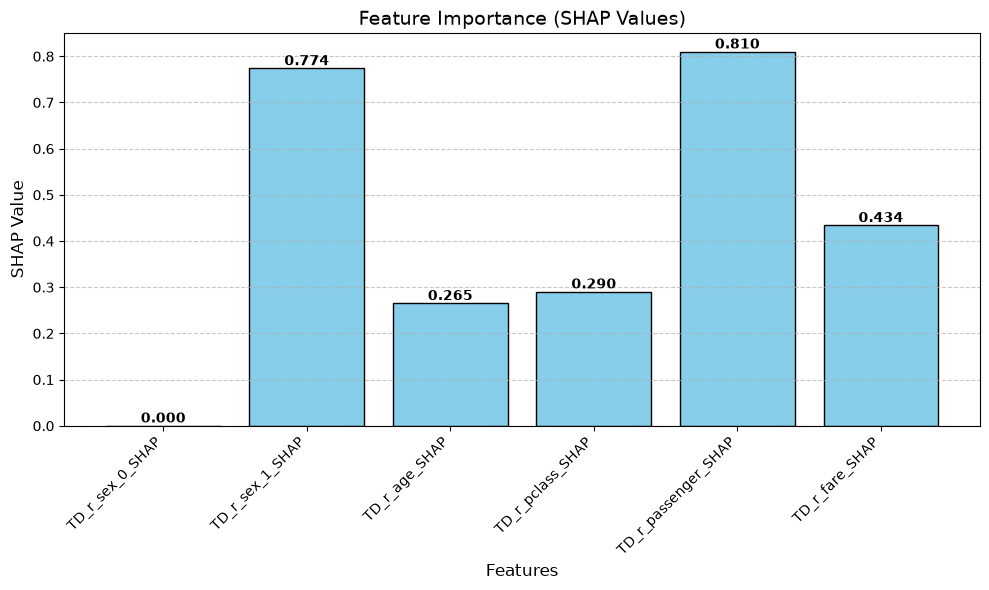

In [12]:
# Generate prediction using data and model rank

prediction = aml.predict(df.iloc[:80], rank=4)

In [13]:
prediction

automl_id,Prediction,Prob_1,Prob_0,survived
206,1,0.7837079391138303,0.21629206088616965,0
46,1,0.9165561803280837,0.08344381967191623,1
266,0,0.4272370351670486,0.5727629648329514,1
102,1,0.9108260622390635,0.08917393776093643,0
222,1,0.7080939660481478,0.29190603395185216,0
38,1,0.8392188084996679,0.1607811915003321,1
230,1,0.9078295306352251,0.09217046936477494,1
90,1,0.5517337302931915,0.44826626970680844,1
158,1,0.882729545772191,0.11727045422780916,0
150,0,0.38631681493229214,0.6136831850677078,1


In [14]:
# Generate performance metrics

performance_metric = aml.evaluate(df.iloc[:80], rank=4)

In [15]:
performance_metric


############ output_data Output ############

   SeqNum              Metric  MetricValue
0       3        Micro-Recall     0.670886
1       5     Macro-Precision     0.725327
2       6        Macro-Recall     0.704545
3       7            Macro-F1     0.668282
4       9     Weighted-Recall     0.670886
5      10         Weighted-F1     0.663445
6       8  Weighted-Precision     0.751539
7       4            Micro-F1     0.670886
8       2     Micro-Precision     0.670886
9       1            Accuracy     0.670886


############ result Output ############

       Prediction  Mapping  CLASS_1  CLASS_2  Precision    Recall        F1  Support
SeqNum                                                                              
0               0  CLASS_1       23        3   0.884615  0.500000  0.638889       46
1               1  CLASS_2       23       30   0.566038  0.909091  0.697674       33


## <b><span style='color:#F1A424'>| 2.</span> Loading Deployed Models - 'mixed_models' </b>

### <b><span style='color:#F1A424'>| 2.1.</span> Loading Model </b>

In [16]:
# Loading models

models_2 = aml.load('mixed_models')

In [17]:
models_2

,RANK,MODEL_ID,FEATURE_SELECTION,ACCURACY,MICRO-PRECISION,MICRO-RECALL,MICRO-F1,MACRO-PRECISION,MACRO-RECALL,MACRO-F1,WEIGHTED-PRECISION,WEIGHTED-RECALL,WEIGHTED-F1,DATA_TABLE
0,1,GLM_3,pca,0.803150,0.803150,0.803150,0.803150,0.806771,0.771455,0.781472,0.804712,0.803150,0.797188,automl__survived_pca_179255112963359
1,2,XGBOOST_2,rfe,0.779528,0.779528,0.779528,0.779528,0.769066,0.778781,0.772051,0.786912,0.779528,0.781478,automl__survived_rfe_179255162347390
2,3,DECISIONFOREST_3,pca,0.763780,0.763780,0.763780,0.763780,0.751064,0.746991,0.748813,0.762238,0.763780,0.762814,automl__survived_pca_179255112963359
3,4,XGBOOST_1,pca,0.740157,0.740157,0.740157,0.740157,0.732009,0.742936,0.733549,0.753491,0.740157,0.743131,automl__survived_pca_179255112963359


### <b><span style='color:#F1A424'>| 2.2.</span> Generating Prediction & Performance Metrics</b>

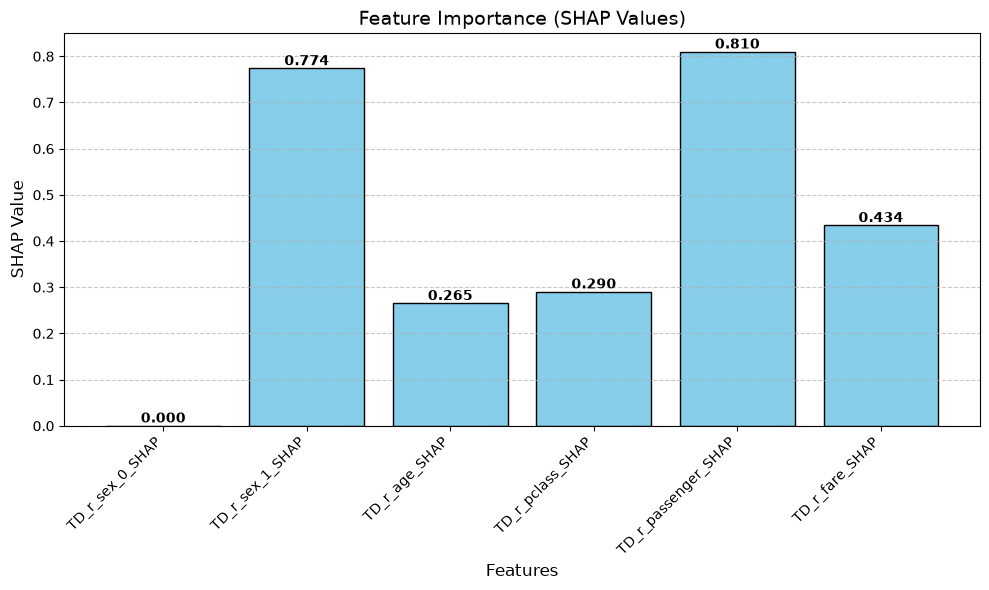

In [18]:
# Generate prediction using data and model rank

prediction = aml.predict(df.iloc[:80], rank=2)

In [19]:
prediction

automl_id,Prediction,Prob_1,Prob_0,survived
204,1,0.7837079391138303,0.21629206088616965,0
44,1,0.9165561803280837,0.08344381967191623,1
264,0,0.4272370351670486,0.5727629648329514,1
100,1,0.9108260622390635,0.08917393776093643,0
220,1,0.7080939660481478,0.29190603395185216,0
36,1,0.8392188084996679,0.1607811915003321,1
60,1,0.7808906309196539,0.21910936908034612,0
212,1,0.7568141352838681,0.24318586471613193,1
120,0,0.4513616418942357,0.5486383581057643,0
280,0,0.40030762708022277,0.5996923729197772,0


In [20]:
# Generate performance metrics

performance_metric = aml.evaluate(df.iloc[:80], rank=2)

In [21]:
performance_metric


############ output_data Output ############

   SeqNum              Metric  MetricValue
0       3        Micro-Recall     0.670886
1       5     Macro-Precision     0.725327
2       6        Macro-Recall     0.704545
3       7            Macro-F1     0.668282
4       9     Weighted-Recall     0.670886
5      10         Weighted-F1     0.663445
6       8  Weighted-Precision     0.751539
7       4            Micro-F1     0.670886
8       2     Micro-Precision     0.670886
9       1            Accuracy     0.670886


############ result Output ############

       Prediction  Mapping  CLASS_1  CLASS_2  Precision    Recall        F1  Support
SeqNum                                                                              
1               1  CLASS_2       23       30   0.566038  0.909091  0.697674       33
0               0  CLASS_1       23        3   0.884615  0.500000  0.638889       46


## <b><span style='color:#F1A424'>| 3.</span> Loading Deployed Models - 'range_models' </b>

### <b><span style='color:#F1A424'>| 3.1.</span> Loading Model</b>

In [22]:
# Creating another AutoML object

obj=ctx.AutoML()

In [23]:
# Loading models

models_3 = obj.load('range_models')

In [24]:
models_3

,RANK,MODEL_ID,FEATURE_SELECTION,ACCURACY,MICRO-PRECISION,MICRO-RECALL,MICRO-F1,MACRO-PRECISION,MACRO-RECALL,MACRO-F1,WEIGHTED-PRECISION,WEIGHTED-RECALL,WEIGHTED-F1,DATA_TABLE
0,1,XGBOOST_2,rfe,0.779528,0.779528,0.779528,0.779528,0.769066,0.778781,0.772051,0.786912,0.779528,0.781478,automl__survived_rfe_179256613520359
1,2,DECISIONFOREST_0,rfe,0.779528,0.779528,0.779528,0.779528,0.767399,0.767399,0.767399,0.779528,0.779528,0.779528,automl__survived_rfe_179256613520359
2,3,DECISIONFOREST_1,pca,0.763780,0.763780,0.763780,0.763780,0.751064,0.746991,0.748813,0.762238,0.763780,0.762814,automl__survived_pca_179255321898880
3,4,DECISIONFOREST_3,pca,0.763780,0.763780,0.763780,0.763780,0.751064,0.746991,0.748813,0.762238,0.763780,0.762814,automl__survived_pca_179255321898880


### <b><span style='color:#F1A424'>| 3.2.</span> Generating Prediction & Performance Metrics</b>

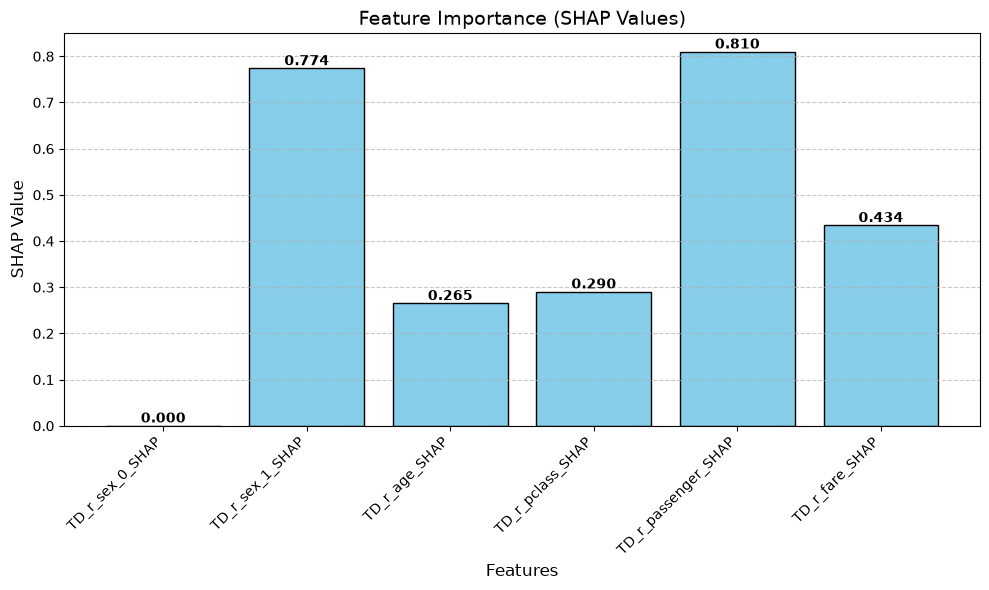

In [25]:
# Generate prediction using data and model rank

prediction = obj.predict(df.iloc[:80], rank=1)

In [26]:
prediction

automl_id,Prediction,Prob_1,Prob_0,survived
122,0,0.4513616418942357,0.5486383581057643,0
182,1,0.8373235564365622,0.16267644356343786,1
126,1,0.6805297528691657,0.3194702471308342,0
118,1,0.8454409582302214,0.15455904176977872,1
186,0,0.3931133704443404,0.6068866295556596,0
94,1,0.8216465804071152,0.17835341959288475,1
106,1,0.8814424784162768,0.11855752158372337,1
58,1,0.5621536343116655,0.4378463656883345,0
70,1,0.8074175610843275,0.19258243891567264,0
46,1,0.9165561803280837,0.08344381967191623,1


In [27]:
# Generate performance metrics

performance_metric = obj.evaluate(df.iloc[:80], rank=1)

In [28]:
performance_metric


############ output_data Output ############

   SeqNum              Metric  MetricValue
0       3        Micro-Recall     0.670886
1       5     Macro-Precision     0.725327
2       6        Macro-Recall     0.704545
3       7            Macro-F1     0.668282
4       9     Weighted-Recall     0.670886
5      10         Weighted-F1     0.663445
6       8  Weighted-Precision     0.751539
7       4            Micro-F1     0.670886
8       2     Micro-Precision     0.670886
9       1            Accuracy     0.670886


############ result Output ############

       Prediction  Mapping  CLASS_1  CLASS_2  Precision    Recall        F1  Support
SeqNum                                                                              
1               1  CLASS_2       23       30   0.566038  0.909091  0.697674       33
0               0  CLASS_1       23        3   0.884615  0.500000  0.638889       46


In [29]:
ctx.remove_context()

True